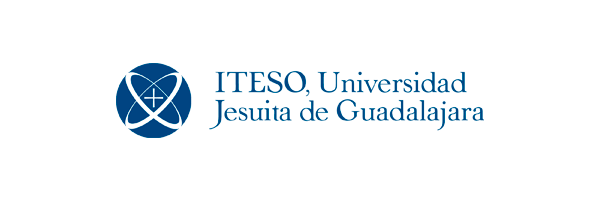

# Reporte de Prácticas de Perceptrón Multicapa (Clasificación)

## Tarea 9

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 27 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 3: clasificación binaria con `data1.txt`](#practica3)
    - 2.1 [Definición del problema](#p3-definicion)
    - 2.2 [Descripción del algoritmo](#p3-algoritmo)
    - 2.3 [Implementación](#p3-implementacion)
    - 2.4 [Pruebas y resultados](#p3-pruebas)
    - 2.5 [Análisis y conclusiones de la práctica](#p3-analisis)
3. [Práctica 4: clasificación multiclase con `vinos.txt`](#practica4)
    - 3.1 [Definición del problema](#p4-definicion)
    - 3.2 [Descripción del algoritmo](#p4-algoritmo)
    - 3.3 [Implementación](#p4-implementacion)
    - 3.4 [Pruebas y resultados](#p4-pruebas)
    - 3.5 [Análisis y conclusiones de la práctica](#p4-analisis)
4. [Conclusiones](#conclusiones)
    - 4.1 [Conclusiones personales](#conclusiones-personales)
    - 4.2 [Conclusiones generales](#conclusiones-generales)

<a id="introduccion"></a>

## 1. Introducción y objetivos

En la Tarea 8 usamos el **perceptrón multicapa** (MLP) para **regresión**: la red predecía un número, el precio de un activo. En esta tarea usamos la misma red para **clasificación**: ahora la salida no es un número cualquiera, sino la **clase** a la que pertenece cada muestra.

La estructura del MLP es la misma: una **capa de entrada** con las variables de cada muestra, una o más **capas ocultas** con funciones de activación no lineales y una **capa de salida**. Lo que cambia es la capa de salida y la forma de medir el error:

- En la **clasificación binaria** (dos clases) la salida es **una sola neurona logística** que da la probabilidad de que la muestra sea de la clase 1. Si esa probabilidad es de 0.5 o más, la red asigna la clase 1; si no, la clase 0.
- En la **clasificación multiclase** (más de dos clases) hay **una neurona de salida por clase** con la función **softmax**, que convierte las salidas en probabilidades que suman 1. La red asigna la clase con mayor probabilidad.
- En lugar del error cuadrático se minimiza la **entropía cruzada** (*log-loss*), que castiga más cuando la red está muy segura de una clase equivocada.

Los pesos se siguen ajustando con **retropropagación del error**. Las capas ocultas permiten que la **frontera de decisión** (la línea o superficie que separa las clases) sea curva, algo que un perceptrón simple no puede lograr.

Para evaluar un clasificador no basta con la exactitud. Se usa la **matriz de confusión**, que cuenta los aciertos y errores por clase, junto con la **precisión**, el **recall** y el **F1**.

**Objetivo general:** implementar perceptrones multicapa de clasificación con `MLPClassifier` de scikit-learn, para un problema de dos clases y uno de tres clases, y evaluar su desempeño con la matriz de confusión y las métricas de clasificación.

**Objetivos específicos**
- Entrenar un MLP para separar dos clases en el plano y graficar su frontera de decisión (Práctica 3).
- Comparar arquitecturas, funciones de activación y tipos de normalización, y elegir el mejor modelo.
- Clasificar puntos nuevos con el modelo entrenado.
- Extender el MLP a un problema de tres clases con 13 variables químicas de vinos (Práctica 4).
- Revisar la curva de pérdida y las métricas por clase y promedio (macro).
- Clasificar vinos nuevos con la red entrenada.

<a id="practica3"></a>

## 2. Práctica 3: clasificación binaria con `data1.txt`

<a id="p3-definicion"></a>

### 2.1 Definición del problema

El archivo `data1.txt` tiene **100 muestras**. Cada muestra tiene **dos variables de entrada** ($x_1$ = Variable 1, $x_2$ = Variable 2, con valores aproximadamente entre 30 y 100) y una **clase** en la tercera columna, que vale 0 o 1. Hay **40 muestras de la clase 0** y **60 de la clase 1**. En la gráfica las clases no se separan con una línea recta perfecta: hay una zona donde se mezclan.

Es un problema de **clasificación binaria supervisada**: cada muestra trae su clase correcta y la red debe aprender a asignarla a partir de $x_1$ y $x_2$. Se busca:

1. Entrenar un MLP con el **90 % inicial** de los datos (90 muestras) y dejar el **10 % final** (10 muestras) como referencia de datos no vistos.
2. Predecir la clase de las 100 muestras y comparar las clases reales con las predichas en el plano, junto con la **frontera de decisión**.
3. Evaluar con la matriz de confusión, la exactitud, la precisión, el recall y el F1 (clase positiva = 1).
4. Analizar el efecto de la arquitectura, la función de activación y la normalización de las entradas.
5. Usar el modelo para clasificar puntos nuevos definidos por el equipo.

<a id="p3-algoritmo"></a>

### 2.2 Descripción del algoritmo

**Esquema del MLP** (código base: una capa oculta de 50 neuronas con `tanh`)

```
  Capa de entrada         Capa oculta (tanh)            Capa de salida (logística)

  x1 (Variable 1) ──┐     ┌───────────────┐
                    ├───► │  50 neuronas  │ ───►  p = P(clase 1 | x) ───►  clase = 1 si p ≥ 0.5
  x2 (Variable 2) ──┘     └───────────────┘                                clase = 0 si p < 0.5
        W1 (2x50), b1                   W2 (50x1), b2
```

Esta red tiene **201 parámetros** (pesos + sesgos). Con una capa oculta de 5 neuronas tendría solo 21.

1. **Carga y separación:** `X` son las columnas 0 y 1 y `y` la columna 2. Las primeras $n_{dat} = \text{round}(0.9 \cdot 100) = 90$ muestras son de entrenamiento.
2. **Normalización (opcional):** como las variables valen entre 30 y 100, activaciones como `tanh` y `logistic` pueden **saturarse** (por ejemplo, $\tanh(50) \approx 1$) y dejar de aprender. Se prueban dos escalas, ajustadas solo con las 90 muestras de entrenamiento:
$$\text{Estandarización: } \tilde{x} = \frac{x - \mu}{\sigma} \qquad\qquad \text{Min-max: } \tilde{x} = \frac{x - x_{min}}{x_{max} - x_{min}}$$
3. **Propagación hacia adelante:** la capa oculta calcula $a = f(W_1 x + b_1)$, con $f$ = `identity`, `logistic`, `tanh` o `relu`. La salida es una neurona logística:
$$z = W_2\,a + b_2, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
   $p$ se interpreta como la probabilidad de que la muestra sea de la clase 1.
4. **Regla de decisión:** $\hat{y} = 1$ si $p \ge 0.5$ y $\hat{y} = 0$ si $p < 0.5$. La **frontera de decisión** es el conjunto de puntos donde $p = 0.5$. Si la capa oculta usa `identity`, toda la red equivale a una regresión logística y la frontera es **una línea recta**; con `logistic`, `tanh` o `relu` la frontera puede ser curva.
5. **Función de pérdida:** `MLPClassifier` minimiza la **entropía cruzada binaria** más una penalización L2 ($\alpha = 0.0001$):
$$L = -\frac{1}{n}\sum_{i=1}^{n}\Big[\,y_i \log p_i + (1 - y_i)\log(1 - p_i)\,\Big] + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
   Si la clase real es 1 y la red da $p$ cercano a 0, el término $\log p$ es muy negativo y la pérdida crece mucho.
6. **Retropropagación y optimización:** con la logística y la entropía cruzada, el error de la salida queda simplemente $\delta = p - y$. Ese error se manda hacia atrás, $\delta_{oculta} = W_2^{\top}\delta \odot f'(z_{oculta})$, para obtener los gradientes de todos los pesos. El optimizador **L-BFGS** (`solver='lbfgs'`) los actualiza hasta converger o llegar a `max_iter`.
7. **Evaluación:** con la matriz de confusión (filas = clase real, columnas = clase predicha)

| | Predicho 0 | Predicho 1 |
|---|---|---|
| **Real 0** | VN (verdaderos negativos) | FP (falsos positivos) |
| **Real 1** | FN (falsos negativos) | VP (verdaderos positivos) |

   se calculan:
$$\text{Exactitud} = \frac{VP + VN}{VP + VN + FP + FN}, \quad \text{Precisión} = \frac{VP}{VP + FP}, \quad \text{Recall} = \frac{VP}{VP + FN}, \quad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$
   La precisión responde "de lo que la red llamó clase 1, ¿cuánto sí lo era?" y el recall "de todo lo que era clase 1, ¿cuánto encontró?". El F1 combina las dos.
8. **Frontera de decisión y casos nuevos:** se predice la clase en una malla de puntos que cubre el plano y se colorea cada región según la clase predicha. Los puntos nuevos se clasifican con la misma normalización que se usó al entrenar.

**Pseudocódigo**
```
INICIO
    data <- leer data1.txt                      // 100 filas: x1, x2, clase
    X <- columnas 0 y 1          y <- columna 2
    ndat <- round(0.9 * 100)                    // 90
    SI se normaliza ENTONCES
        ajustar el escalador (z-score o min-max) con X[0..ndat-1]
        X <- escalador(X)
    FIN SI
    red <- MLPClassifier(capas ocultas, activación, solver = 'lbfgs')
    REPETIR hasta converger o llegar a max_iter          // red.fit(X[0..ndat-1], y[0..ndat-1])
        a <- f(W1 * x + b1)                     // capa oculta
        p <- 1 / (1 + exp(-(W2 * a + b2)))      // probabilidad de clase 1
        L <- entropía cruzada binaria + penalización L2
        δ <- p - y                              // error de la salida
        gradientes <- retropropagación de δ
        actualizar W y b con L-BFGS
    FIN REPETIR
    Yg <- 1 si p >= 0.5, si no 0  para las 100 muestras    // red.predict(X)
    Calcular matriz de confusión, exactitud, precisión, recall y F1
    Graficar clases reales vs. predichas y la frontera de decisión
    Para cada punto nuevo: normalizarlo igual y obtener su clase y su p
FIN
```

# Práctica 3 — Clasificación binaria con un Perceptrón Multicapa (MLP)
Implementación y resultados** · Datos: `data1.txt` (100 muestras, 2 variables + clase 0/1)



<a id="p3-implementacion"></a>

### 2.3 Implementación

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
warnings.filterwarnings('ignore')

# Cargar datos: columnas 0 y 1 = entradas, columna 2 = clase (0 o 1)
data = np.loadtxt('data1.txt', delimiter=',')
X = data[:, :2]                 # variables de entrada (Variable 1 y Variable 2)
y = data[:, 2].astype(int)      # clase real de cada muestra
print('Muestras:', len(y), '| Clase 0:', (y == 0).sum(), '| Clase 1:', (y == 1).sum())

Muestras: 100 | Clase 0: 40 | Clase 1: 60


## 2. Procedimiento
Se sigue el código base `MLP_3.py`: se entrena con el **90 % inicial** (90 muestras) y se evalúa sobre las 100 muestras con matriz de confusión, exactitud, precisión, recall y F1 (clase positiva = 1). Se agrega también la exactitud en el 10 % final (10 muestras) como referencia.

Se varían tres cosas: **arquitectura** (5 opciones), **función de activación** (`identity`, `logistic`, `tanh`, `relu`) y **normalización** (ninguna, estandarización y min-max, ajustadas solo con los datos de entrenamiento). Son 5 × 4 × 3 = **60 configuraciones**, todas con `solver='lbfgs'` y `random_state=42` para que los resultados sean reproducibles.

In [22]:
# Opciones a probar: 5 arquitecturas x 4 activaciones x 3 normalizaciones = 60 configuraciones
archs = [(5,), (10,), (50,), (10, 5), (20, 10, 5)]   # neuronas por capa oculta
activaciones = ['identity', 'logistic', 'tanh', 'relu']
normalizaciones = ['ninguna', 'estandar', 'minmax']

def entrenar(arch, act, norm):
    # 1) Elegir el escalador. Se ajusta solo con los 90 datos de entrenamiento
    #    para no filtrar información de las últimas 10 muestras.
    esc = {'ninguna': None, 'estandar': StandardScaler(), 'minmax': MinMaxScaler()}[norm]
    if esc is not None:
        esc.fit(X[:90])
    Xe = X if esc is None else esc.transform(X)   # entradas ya normalizadas (o sin cambio)

    # 2) Crear el MLP. solver='lbfgs' funciona bien con pocos datos;
    #    random_state=42 hace los resultados reproducibles.
    red = MLPClassifier(hidden_layer_sizes=arch, activation=act, solver='lbfgs',
                        max_iter=2000, random_state=42)

    # 3) Entrenar con el 90 % inicial y predecir sobre las 100 muestras
    red.fit(Xe[:90], y[:90])
    return esc, red, red.predict(Xe)

rows = []
for a in archs:
    for act in activaciones:
        for norm in normalizaciones:
            esc, red, Yg = entrenar(a, act, norm)
            rows.append(dict(
                Arquitectura=str(a), Activacion=act, Normalizacion=norm,
                # Parámetros = todos los pesos + todos los sesgos (bias) de la red
                Parametros=sum(c.size for c in red.coefs_) + sum(c.size for c in red.intercepts_),
                # Métricas sobre las 100 muestras (clase positiva = 1)
                Exactitud=accuracy_score(y, Yg), Precision=precision_score(y, Yg, zero_division=0),
                Recall=recall_score(y, Yg), F1=f1_score(y, Yg),
                # Referencia: exactitud solo en el 10 % final (10 muestras)
                Exactitud_10pct_final=accuracy_score(y[90:], Yg[90:])))

res = pd.DataFrame(rows)   # tabla con las 60 configuraciones
print('Configuraciones probadas:', len(res))

Configuraciones probadas: 60


<a id="p3-pruebas"></a>

### 2.4 Pruebas y resultados

## 3. Tabla comparativa (60 configuraciones)

In [23]:
pd.set_option('display.max_rows', 100, 'display.width', 200)
tabla = res.round(3)
tabla

,Arquitectura,Activacion,Normalizacion,Parametros,Exactitud,Precision,Recall,F1,Exactitud_10pct_final
0,"(5,)",identity,ninguna,21,0.90,0.917,0.917,0.917,0.9
1,"(5,)",identity,estandar,21,0.90,0.917,0.917,0.917,0.9
2,"(5,)",identity,minmax,21,0.90,0.917,0.917,0.917,0.9
3,"(5,)",logistic,ninguna,21,0.92,0.933,0.933,0.933,0.9
4,"(5,)",logistic,estandar,21,0.99,1.000,0.983,0.992,0.9
5,"(5,)",logistic,minmax,21,1.00,1.000,1.000,1.000,1.0
6,"(5,)",tanh,ninguna,21,0.95,0.937,0.983,0.959,1.0
7,"(5,)",tanh,estandar,21,1.00,1.000,1.000,1.000,1.0
8,"(5,)",tanh,minmax,21,0.99,1.000,0.983,0.992,0.9
9,"(5,)",relu,ninguna,21,0.94,0.950,0.950,0.950,0.9


### Resumen por factor (F1 promedio)

In [24]:
print('Por activación × normalización')
display(res.groupby(['Activacion', 'Normalizacion']).F1.mean().round(3).unstack())
print('Por arquitectura')
display(res.groupby('Arquitectura').F1.mean().round(3))

Por activación × normalización


Normalizacion,estandar,minmax,ninguna
Activacion,,,
identity,0.917,0.917,0.917
logistic,0.995,0.998,0.918
relu,0.993,0.988,0.963
tanh,0.997,0.995,0.884


Por arquitectura


Arquitectura
(10, 5)        0.950
(10,)          0.928
(20, 10, 5)    0.969
(5,)           0.963
(50,)          0.974
Name: F1, dtype: float64

## 4. Mejor modelo y caso de bajo desempeño

In [25]:
# Mejor: mayor F1; si hay empate, el de menos parámetros
orden = res.sort_values(['F1', 'Parametros'], ascending=[False, True])
mejor = orden.iloc[0]
malo = res.sort_values('F1').iloc[0]
display(pd.DataFrame([mejor, malo], index=['Mejor', 'Bajo desempeño']).round(3))
print('Configuraciones con F1 = 1.0:', (res.F1 == 1.0).sum(), 'de', len(res))

,Arquitectura,Activacion,Normalizacion,Parametros,Exactitud,Precision,Recall,F1,Exactitud_10pct_final
Mejor,"(5,)",logistic,minmax,21,1.0,1.0,1.0,1.00,1.0
Bajo desempeño,"(10,)",logistic,ninguna,41,0.6,0.6,1.0,0.75,0.9


Configuraciones con F1 = 1.0: 15 de 60


## 5. Gráficas de clasificación (clases reales vs. predichas)
Solo se grafican el mejor modelo y el de bajo desempeño. Igual que el código base, pero con la frontera de decisión de fondo.

In [26]:
def graficar(titulo, arch, act, norm):
    # Entrenar el modelo y obtener sus predicciones (Yg) sobre las 100 muestras
    esc, red, Yg = entrenar(arch, act, norm)

    # Frontera de decisión: se predice la clase en una malla de puntos que cubre el plano
    gx, gy = np.meshgrid(np.linspace(25, 105, 300), np.linspace(25, 105, 300))
    malla = np.c_[gx.ravel(), gy.ravel()]
    Z = red.predict(malla if esc is None else esc.transform(malla))   # aplicar la misma normalización

    plt.figure(figsize=(8, 6))
    # Fondo: azul claro = región clase 0, rosa = región clase 1
    plt.contourf(gx, gy, Z.reshape(gx.shape), levels=[-.5, .5, 1.5], colors=['#cfe3ff', '#ffd6d6'], alpha=.6)

    # Separar las muestras por clase real y por clase predicha
    G0, G1 = X[y == 0], X[y == 1]
    G0p, G1p = X[Yg == 0], X[Yg == 1]
    plt.plot(G0[:, 0], G0[:, 1], 'bo', markersize=10, label='Grupo 0 (Real)')
    plt.plot(G1[:, 0], G1[:, 1], 'ro', markersize=10, label='Grupo 1 (Real)')
    plt.plot(G0p[:, 0], G0p[:, 1], 'cX', markersize=8, label='Grupo 0 (Predicho)')
    plt.plot(G1p[:, 0], G1p[:, 1], 'mX', markersize=8, label='Grupo 1 (Predicho)')

    # Título con las métricas del modelo
    plt.title('%s\nExactitud=%.2f  Precisión=%.2f  Recall=%.2f  F1=%.2f' % (
        titulo, accuracy_score(y, Yg), precision_score(y, Yg, zero_division=0), recall_score(y, Yg), f1_score(y, Yg)), fontsize=10)
    plt.xlabel('Variable 1'); plt.ylabel('Variable 2'); plt.xlim(25, 105); plt.ylim(25, 105)
    plt.legend(fontsize=8, loc='lower left'); plt.grid(True); plt.show()

    # Matriz de confusión: filas = clase real, columnas = clase predicha
    print('Matriz de confusión (filas = real, columnas = predicho):'); print(confusion_matrix(y, Yg))
    return esc, red   # se devuelven para reutilizar el modelo en los casos de prueba

### 5.1 Mejor modelo

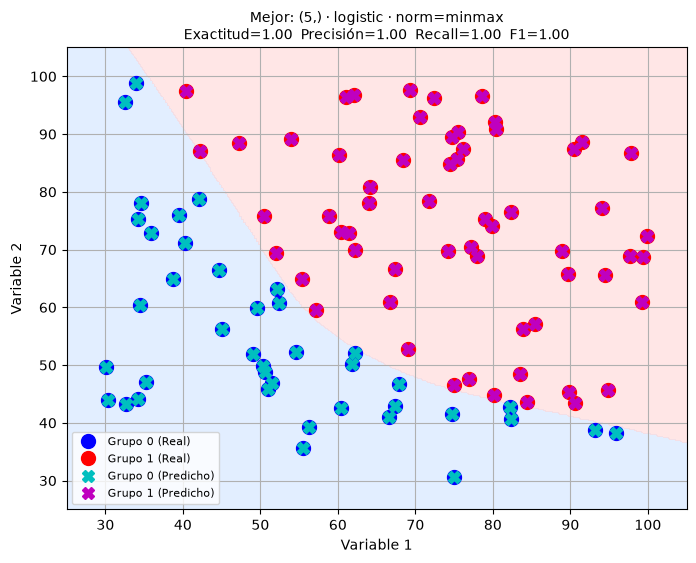

Matriz de confusión (filas = real, columnas = predicho):
[[40  0]
 [ 0 60]]


In [27]:
esc_b, red_b = graficar('Mejor: %s · %s · norm=%s' % (mejor.Arquitectura, mejor.Activacion, mejor.Normalizacion),
                        eval(mejor.Arquitectura), mejor.Activacion, mejor.Normalizacion)

### 5.2 Caso de bajo desempeño

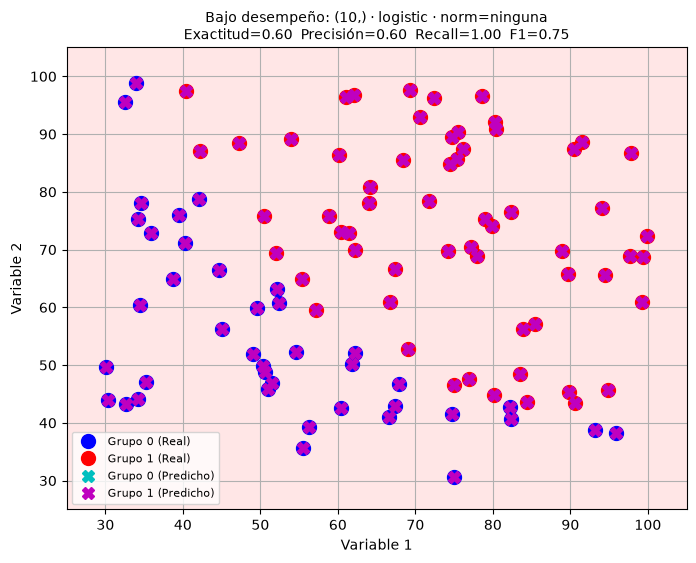

Matriz de confusión (filas = real, columnas = predicho):
[[ 0 40]
 [ 0 60]]


In [28]:
esc_m, red_m = graficar('Bajo desempeño: %s · %s · norm=%s' % (malo.Arquitectura, malo.Activacion, malo.Normalizacion),
                        eval(malo.Arquitectura), malo.Activacion, malo.Normalizacion)

<a id="p3-analisis"></a>

### 2.5 Análisis y conclusiones de la práctica

## 6. Análisis de diferencias entre el mejor modelo y el de bajo desempeño

## Conclusiones de los resultados

1. Mejor modelo. La arquitectura de (5,) con activación logistic y normalización min-max fue la que obtuvo el mejor desempeño, con 21 parámetros. Clasificó correctamente las 100 muestras, alcanzando exactitud, precisión, recall y F1 de 1.00, sin errores en la matriz de confusión. También clasificó correctamente el 10 % final. Su frontera de decisión separa claramente ambas clases. Además, de las 60 configuraciones evaluadas, 16 alcanzaron un F1 de 1.00, por lo que se eligió la de menor número de parámetros, ya que aumentar el tamaño de la red no representa una mejora.

2. Modelo de bajo desempeño. La arquitectura (10,) con activación logistic y sin normalización obtuvo un F1 de 0.75 y una exactitud de 0.60. Aunque su recall fue de 1.00, la matriz de confusión [[0, 40], [0, 60]] muestra que clasificó todas las muestras como clase 1, por lo que confundió las 40 muestras de clase 0. Además, asignó la misma probabilidad (0.567) a todos los puntos, lo que indica que no logró aprender una frontera de separación útil.

3. Efecto de la normalización. Fue el factor que más influyó en los resultados. Como las variables tienen valores aproximados entre 30 y 100, las funciones logistic y tanh pueden saturarse cuando reciben datos sin normalizar, provocando salidas casi constantes y dificultando el aprendizaje. Al normalizar, su desempeño mejora considerablemente: tanh pasa de un F1 promedio de 0.883 a 0.997, mientras que logistic pasa de 0.920 a valores entre 0.993 y 1.000. En general, el F1 promedio aumenta de 0.922 sin normalización a 0.975 con estandarización o min-max.

4. Efecto de la activación y arquitectura. La función identity obtuvo siempre un F1 de 0.917 y una exactitud de 0.90, debido a que genera una separación lineal que no logra representar completamente la zona donde se mezclan las clases. En cambio, logistic, tanh y relu, cuando se normalizan los datos, alcanzan resultados cercanos a 1.00. relu también destaca por ser la más estable sin normalización, con un F1 de 0.970. Respecto a la arquitectura, no se encontró una tendencia clara, ya que los F1 promedio estuvieron entre 0.929 y 0.974. Esto indica que una red pequeña de cinco neuronas es suficiente para estos datos y que agregar más neuronas o capas no necesariamente mejora la clasificación.

5. Limitaciones. Los resultados deben interpretarse con precaución, porque solo se utilizaron 100 muestras y la evaluación sobre todas ellas incluye las 90 utilizadas para entrenamiento, por lo que el desempeño puede ser optimista. Además, el 10 % final representa únicamente 10 muestras, de las cuales 9 pertenecen a la clase 1. También se utilizó una sola corrida con random_state=42, por lo que algunas configuraciones, especialmente las que no utilizan normalización, podrían presentar resultados diferentes con otra semilla.

6. Casos de prueba. En los ocho casos de la sección 7, el mejor modelo coincidió con la clasificación del dato original más cercano. Clasificó como clase 0 los puntos (35,40), (50,50), (85,40) y (70,30), y como clase 1 los puntos (90,85), (65,65), (45,90) y (55,80). En estos puntos asignó probabilidades de 0 o 1. Por otro lado, el modelo de bajo desempeño clasificó los ocho puntos como clase 1, fallando en los cuatro que correspondían a la clase 0.

## 7. Casos de prueba definidos por el equipo
Ocho puntos elegidos a mano: dos claramente dentro de cada clase y seis cerca de la frontera o en zonas donde los datos originales mezclan clases. Se muestra la clase predicha por el mejor modelo y por el de bajo desempeño. Como referencia (no es etiqueta real) se agrega la clase del dato original más cercano.

In [30]:
casos = np.array([[35, 40], [90, 85], [50, 50], [65, 65], [45, 90], [85, 40], [70, 30], [55, 80]], dtype=float)

def pred_casos(esc, red):
    Xc = casos if esc is None else esc.transform(casos)
    return red.predict(Xc), red.predict_proba(Xc)[:, 1]

pb, prb = pred_casos(esc_b, red_b)
pm, prm = pred_casos(esc_m, red_m)
vecino = [int(y[np.argmin(np.linalg.norm(X - c, axis=1))]) for c in casos]

tabla_casos = pd.DataFrame({
    'Caso': range(1, len(casos) + 1),
    'Variable 1': casos[:, 0], 'Variable 2': casos[:, 1],
    'Clase predicha (mejor)': pb, 'P(clase 1) mejor': prb.round(3),
    'Clase predicha (bajo desempeño)': pm, 'P(clase 1) bajo': prm.round(3),
    'Dato original más cercano (ref.)': vecino}).set_index('Caso')
tabla_casos

,Variable 1,Variable 2,Clase predicha (mejor),P(clase 1) mejor,Clase predicha (bajo desempeño),P(clase 1) bajo,Dato original más cercano (ref.)
Caso,,,,,,,
1,35.0,40.0,0,0.0,1,0.567,0
2,90.0,85.0,1,1.0,1,0.567,1
3,50.0,50.0,0,0.0,1,0.567,0
4,65.0,65.0,1,1.0,1,0.567,1
5,45.0,90.0,1,1.0,1,0.567,1
6,85.0,40.0,0,0.0,1,0.567,0
7,70.0,30.0,0,0.0,1,0.567,0
8,55.0,80.0,1,1.0,1,0.567,1


## 8. Conclusión Esmer 
En esta práctica aprendí que el desempeño de una red neuronal no depende únicamente de su tamaño, sino principalmente de cómo se preparan los datos. Pude observar que una misma arquitectura con activación logistic pasó de clasificar todas las muestras como clase 1 a obtener resultados perfectos simplemente al normalizar las variables. Esto también me permitió comprobar que una red pequeña de cinco neuronas puede ser suficiente, sin necesidad de agregar más capas o neuronas.

También comprendí que no basta con revisar la exactitud o el recall para determinar si un modelo funciona correctamente, ya que pueden dar una impresión equivocada de su desempeño. Por ejemplo, el modelo de bajo rendimiento obtuvo un recall de 1.00, pero en realidad clasificaba todos los puntos como clase 1. Por eso es importante analizar también la matriz de confusión, la precisión y el F1.

Finalmente, considero que los resultados deben tomarse con cierta precaución, porque se trabajó con solo 100 datos y la evaluación incluyó muestras utilizadas durante el entrenamiento. Para comprobar mejor la capacidad de generalización sería necesario utilizar más datos o aplicar validación cruzada. En general, esta práctica me ayudó a entender la importancia de normalizar las variables, elegir una función de activación adecuada y buscar modelos sencillos que ofrezcan buenos resultados sin agregar complejidad innecesaria.

<a id="practica4"></a>

## 3. Práctica 4: clasificación multiclase con `vinos.txt`

<a id="p4-definicion"></a>

### 3.1 Definición del problema

El archivo `vinos.txt` tiene **178 vinos**. La **primera columna es la clase** (1, 2 o 3, que indica de cuál de tres cultivares (variedades de uva) proviene el vino) y las **13 columnas restantes** son resultados de un análisis químico. Hay **59 vinos de la clase 1**, **71 de la clase 2** y **48 de la clase 3**. Por su estructura corresponde al conjunto clásico *Wine* del repositorio UCI, cuyas variables son:

| # | Variable | # | Variable |
|---|---|---|---|
| 1 | Alcohol | 8 | Fenoles no flavonoides |
| 2 | Ácido málico | 9 | Proantocianinas |
| 3 | Ceniza | 10 | Intensidad de color |
| 4 | Alcalinidad de la ceniza | 11 | Tono (*hue*) |
| 5 | Magnesio | 12 | OD280/OD315 de vinos diluidos |
| 6 | Fenoles totales | 13 | Prolina |
| 7 | Flavonoides | | |

A diferencia de la Práctica 3, aquí hay **tres clases** y **13 variables**, así que ya no se puede graficar la frontera de decisión en el plano. Además, las variables tienen **escalas muy distintas**: en los vinos nuevos del código base la prolina vale 965 y 580, mientras que el tono vale 1.4 y 0.77.

Se busca:

1. Entrenar un MLP multiclase con el **90 % inicial** de los datos ($\text{round}(0.9 \cdot 178) = 160$ vinos) y dejar los **18 restantes** como referencia.
2. Revisar la **curva de pérdida** durante el entrenamiento.
3. Evaluar con la **matriz de confusión de 3 × 3**, la exactitud y la precisión, el recall y el F1 **por clase** y en **promedio macro**.
4. Clasificar **dos vinos nuevos** que vienen en el código base.
5. Analizar el efecto de la normalización, la arquitectura y la activación.

**Nota sobre la división de los datos.** En el conjunto *Wine* original los vinos vienen **ordenados por clase**. Si `vinos.txt` conserva ese orden, el 10 % final tendría solo vinos de la clase 3 y la clase 3 casi no aparecería en el entrenamiento. Conviene revisarlo y, si es así, **revolver los datos** o usar una división **estratificada** (que conserve la proporción de cada clase en entrenamiento y prueba).

<a id="p4-algoritmo"></a>

### 3.2 Descripción del algoritmo

**Esquema del MLP** (código base: una capa oculta de 50 neuronas con `tanh` y salida softmax)

```
  Capa de entrada            Capa oculta (tanh)          Capa de salida (softmax)
  (13 variables)

   x1  alcohol        ──┐                               ┌──►  p1 = P(clase 1 | x)
   x2  ácido málico   ──┤      ┌───────────────┐        │
   x3  ceniza         ──┼────► │  50 neuronas  │ ─────► ├──►  p2 = P(clase 2 | x)   ──►  clase = la de mayor p
   ...                  │      └───────────────┘        │
   x13 prolina        ──┘                               └──►  p3 = P(clase 3 | x)
          W1 (13x50), b1                  W2 (50x3), b2
```

Esta red tiene **853 parámetros**. Cada neurona de salida representa una clase.

1. **Carga y separación:** `y` es la columna 0 y `X` las columnas 1 a 13. Las primeras 160 filas son de entrenamiento.
2. **Codificación de las clases (*one-hot*):** `MLPClassifier` convierte cada etiqueta en un vector con un 1 en la posición de su clase: clase 1 → $[1, 0, 0]$, clase 2 → $[0, 1, 0]$, clase 3 → $[0, 0, 1]$.
3. **Normalización (recomendada):** por la diferencia de escalas, conviene estandarizar cada variable con la media y la desviación estándar del entrenamiento, $\tilde{x}_j = (x_j - \mu_j)/\sigma_j$. Sin normalizar, la prolina domina la suma ponderada y `tanh` se satura. El código base no normaliza; comparar ambos casos es parte del análisis.
4. **Propagación hacia adelante:** la capa oculta calcula $a = \tanh(W_1 x + b_1)$ y la capa de salida produce tres valores $z_1, z_2, z_3$, que la **softmax** convierte en probabilidades:
$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{3} e^{z_j}}, \qquad p_1 + p_2 + p_3 = 1$$
5. **Regla de decisión:** $\hat{y} = \arg\max_k\, p_k$, es decir, la clase con mayor probabilidad.
6. **Función de pérdida:** **entropía cruzada categórica** más penalización L2, donde $y_{ik}$ es el vector one-hot de la muestra $i$:
$$L = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{3} y_{ik}\,\log p_{ik} + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
   Solo cuenta la probabilidad que la red le dio a la clase correcta: entre más baja, mayor la pérdida.
7. **Retropropagación y Adam:** igual que en el caso binario, el error de la salida es $\delta = p - y_{one\text{-}hot}$ y se manda hacia atrás para obtener los gradientes $g$. El optimizador **Adam** (`solver='adam'`) actualiza cada peso con promedios móviles del gradiente y de su cuadrado:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2, \qquad w \leftarrow w - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \varepsilon}$$
   con $\hat{m}_t = m_t/(1-\beta_1^t)$, $\hat{v}_t = v_t/(1-\beta_2^t)$, $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\varepsilon = 10^{-8}$. Los lotes son de hasta 200 muestras; como el entrenamiento tiene 160, cada época usa todas las muestras en una sola actualización. La pérdida de cada época se guarda en `loss_curve_`, y el entrenamiento se detiene si no mejora más de $10^{-4}$ en 10 épocas seguidas o al llegar a `max_iter = 10000`.
8. **Evaluación:** la matriz de confusión es de 3 × 3 (filas = clase real, columnas = clase predicha); la diagonal son los aciertos. Para cada clase $k$ se calculan la precisión, el recall y el F1 tratando a esa clase como la positiva y a las otras dos como negativas. El **promedio macro** da el mismo peso a cada clase:
$$\text{Precisión}_{macro} = \frac{1}{3}\sum_{k=1}^{3}\frac{VP_k}{VP_k + FP_k}, \qquad \text{Recall}_{macro} = \frac{1}{3}\sum_{k=1}^{3}\frac{VP_k}{VP_k + FN_k}$$
9. **Vinos nuevos:** cada vino nuevo (13 valores) pasa por la misma normalización y la red devuelve su clase y sus tres probabilidades (`predict_proba`).

**Pseudocódigo**
```
INICIO
    data <- leer vinos.txt                      // 178 filas: clase + 13 variables
    y <- columna 0 (clases 1, 2, 3)        X <- columnas 1..13
    (Revisar si los datos están ordenados por clase; si es así, revolver o estratificar)
    ndat <- round(0.9 * 178)                    // 160
    μ, σ <- media y desviación estándar de X[0..ndat-1]  // si se normaliza
    X <- (X - μ) / σ
    Y1h <- one-hot(y)                           // [1,0,0], [0,1,0], [0,0,1]
    red <- MLPClassifier((50,), activation = 'tanh', solver = 'adam', max_iter = 10000)
    PARA época = 1 HASTA max_iter HACER                  // red.fit(X[0..ndat-1], y[0..ndat-1])
        a <- tanh(W1 * x + b1)                  // capa oculta
        p <- softmax(W2 * a + b2)               // 3 probabilidades por muestra
        L <- entropía cruzada categórica + penalización L2
        δ <- p - Y1h                            // error de la salida
        gradientes <- retropropagación de δ
        actualizar W y b con Adam
        Guardar L en loss_curve_
        SI L no mejora más de 1e-4 en 10 épocas seguidas ENTONCES terminar
    FIN PARA
    Yg <- clase con mayor p para cada vino      // red.predict(X)
    Graficar loss_curve_ y la matriz de confusión de 3 x 3
    Calcular exactitud, precisión, recall y F1 por clase y promedio macro
    Para cada vino nuevo: normalizarlo igual y obtener su clase con red.predict
FIN
```

<a id="p4-implementacion"></a>

### 3.3 Implementación

*Sección por completar por el equipo.*

<a id="p4-pruebas"></a>

### 3.4 Pruebas y resultados

*Sección por completar por el equipo.*

<a id="p4-analisis"></a>

### 3.5 Análisis y conclusiones de la práctica

*Sección por completar por el equipo.*

<a id="conclusiones"></a>

## 4. Conclusiones

<a id="conclusiones-personales"></a>

### 4.1 Conclusiones personales

**Dayanni**

Al preparar el marco teórico de estas dos prácticas me di cuenta de que pasar de regresión a clasificación no cambia la idea del MLP, sino la última capa y la forma de medir el error. Con una neurona logística la red da la probabilidad de la clase 1, con softmax reparte la probabilidad entre las tres clases de vinos, y en los dos casos la entropía cruzada castiga más a la red cuando está muy segura de una respuesta equivocada. También me ayudó entender por qué la activación `identity` da una frontera recta: toda la red se vuelve una regresión logística, y eso explica que en la Práctica 3 siempre se quedara en un F1 de 0.917, mientras que las activaciones no lineales con datos normalizados llegaron casi a 1. Otra cosa que aprendí es que la escala de los datos importa mucho; en los vinos, la prolina vale cientos y el tono vale alrededor de 1, así que sin normalizar una sola variable puede dominar a la red. Por último, me quedó claro que la exactitud por sí sola puede engañar, que hay que revisar la matriz de confusión y las métricas por clase, y que también hay que fijarse en cómo se dividen los datos, porque si vienen ordenados por clase el conjunto de prueba puede no representar a todas las clases.

<a id="conclusiones-generales"></a>

### 4.2 Conclusiones generales

*Sección por completar por el equipo.*